In [9]:
# read text into python, make everything lowercase, remove punctuation (~10s)
def getText():
    valid = 'abcdefghijklmnopqrstuvwxyz '
    with open("AllCombined.txt") as f:
        raw = f.read()
    low = raw.lower().replace("\n", " ")
    letters_only = ''.join(char for char in low if char in valid)
    return letters_only

txt = getText()
print(txt[:500])

 april  april apr is the fourth month of the year in the julian and gregorian calendars and comes between march and may it is one of four months to have  days  april always begins on the same day of the week as july and additionally january in leap years april always ends on the same day of the week as december  april comes between march and may making it the fourth month of the year it also comes first in the year out of the four months that have  days as june september and november are later i


In [10]:
import cupy as np
import numpy as onp

In [11]:
# tokenize and build vocab
from collections import Counter
vocab_sz = 10000
stop_words = ["i", "me", "my", "myself", "we", "our", "ours", "ourselves", "you", "your", "yours", "yourself", "yourselves", "he", "him", "his", "himself", "she", "her", "hers", "herself", "it", "its", "itself", "they", "them", "their", "theirs", "themselves", "what", "which", "who", "whom", "this", "that", "these", "those", "am", "is", "are", "was", "were", "be", "been", "being", "have", "has", "had", "having", "do", "does", "did", "doing", "a", "an", "the", "and", "but", "if", "or", "because", "as", "until", "while", "of", "at", "by", "for", "with", "about", "against", "between", "into", "through", "during", "before", "after", "above", "below", "to", "from", "up", "down", "in", "out", "on", "off", "over", "under", "again", "further", "then", "once", "here", "there", "when", "where", "why", "how", "all", "any", "both", "each", "few", "more", "most", "other", "some", "such", "no", "nor", "not", "only", "own", "same", "so", "than", "too", "very", "s", "t", "can", "will", "just", "don", "should", "now"]

lst = [word for word in txt.split() if word != '']
filtered = [word for word in lst if word not in stop_words]
vocab = [word for word, cnt in Counter(filtered).most_common(vocab_sz) if word not in stop_words]
vocab_sz = len(vocab)

vocab_st = set(vocab)
dict = {word: i for i, word in enumerate(vocab)}
data = [dict[word] for word in filtered if word in vocab_st]
print(data[:20])
print(len(data))
print(len(vocab))
print(len(stop_words))



[63, 63, 588, 876, 50, 3173, 6052, 417, 41, 16, 3, 116, 590, 294, 63, 609, 1843, 134, 1016, 52]
13316348
10000
127


In [12]:
# training data, loop over the text to generate target and context
# import numpy as np
import Neural as Neur
np.random.seed(100)
x = []
y = []
window = 10
for i in range(window, len(data) - window):
    start = i - window
    end = i + window + 1
    context = []
    for j in range(start, end):
        if i != j:
            context.append(data[j])
    x.append(context)
    y.append(data[i])


x = np.array(x)
y = np.array(y)
indices = np.arange(len(x))
np.random.shuffle(indices)
x_shuffled = x[indices]
y_shuffled = y[indices]
end = int(len(x_shuffled) * 0.9)

X_train = x_shuffled[:end]
Y_train = y_shuffled[:end]
X_test = x_shuffled[end:]
Y_test = y_shuffled[end:]
print(len(Y_train))



11984695


In [13]:
# neural network!
import importlib
from tqdm import tqdm
import cupyx
importlib.reload(Neur)

sz = len(Y_train)

def get_cbow(context):
    ctx = np.asarray(context)
    mat = np.zeros((len(ctx), vocab_sz), dtype=np.float32)
    rows = np.repeat(np.arange(len(ctx)), ctx.shape[1])
    cupyx.scatter_add(mat, (rows, ctx.ravel()), np.float32(1.0 / (2 * window)))
    return mat

def get_one_hot(indices):
    mat = np.zeros((len(indices), vocab_sz), dtype=np.float32)
    mat[np.arange(len(indices)), indices] = 1
    return mat



In [14]:
import time
import copy

def step_sgd(N_a, state, g):
    params = N_a.get_params()
    N_a.set_params(params - state['lr'] * g)
    
    state['track'].append(state['lr'])
    return state

def get_mat(N_a, d):
    d1 = N_a.list_layers[0].list_layers[0]
    dim, V = d1.n_sortie, d1.n_entree
    vdot = d[:dim * V].reshape(dim, V)
    b1 = d[dim * V: dim * V + dim]
    udot = d[dim * V + dim: dim * V * 2 + dim].reshape(V, dim)
    b2 = d[dim * V * 2 + dim:]
    return vdot, b1, udot, b2

def curvature(N_a, d):
    N = N_a.list_layers[0]
    l1, l2, loss = N.list_layers[0], N.list_layers[1], N_a.list_layers[1]
    h = l2.save_X
    z = loss.save_X
    xin = l1.save_X
    tar = loss.save_D
    u = l2.A
    vdot, b1, udot, b2 = get_mat(N_a, d)
    
    hdot = vdot @ xin + b1[:, None]
    zdot = udot @ h + u @ hdot + b2[:, None]
    zmax = np.max(z, axis=0)
    p = np.exp(z - zmax)
    p /= np.sum(p, axis=0)
    mu = np.sum(p * zdot, axis=0)
    S = np.sum(p * zdot**2, axis=0)
    gdot = udot.T @ (p - tar)
    kappa = (S - mu**2) + 2.0 * np.sum(gdot * hdot, axis=0)
    return kappa

def step_red(N_a, state, g, lv, X):
    beta3, ell, eps = 0.9, 6.0, 1e-4
    
    p = N_a.get_params()
    d = g
    nrm2 = np.dot(d, d)

    kappa = curvature(N_a, d)
    ck = max(float(np.mean(np.abs(kappa))) / nrm2, 1e-20)
    
    state['chat'] = beta3 * state['chat'] + (1 - beta3) * ck
    ctilde = state['chat'] / (1 - beta3 ** (state['k'] + 1))
    Lk = max(ctilde, ck)
    rk = np.dot(d, g) / (2 * nrm2 * Lk)

    l1, l2 = N_a.list_layers[0].list_layers[0], N_a.list_layers[0].list_layers[1]
    B = float(max(np.linalg.norm(l1.A, axis=0).max(), np.linalg.norm(l2.A, axis=1).max()))
    state['track'].append((float(np.mean(kappa) / nrm2), B, float(rk)))
    
    N_a.set_params(p - ell * rk * d)
    state['k'] += 1
    return state

def step_adam(N_a, state, g):
    b1, b2, e = 0.9, 0.999, 1e-8

    state['m'] = b1 * state['m'] + (1 - b1) * g
    state['v'] = b2 * state['v'] + (1 - b2) * g**2
    mh = state['m'] / (1 - b1 ** (state['k'] + 1))
    vh = state['v'] / (1 - b2 ** (state['k'] + 1))

    p = N_a.get_params()
    p -= state['lr'] * mh / (np.sqrt(vh) + e)
    N_a.set_params(p)
    state['k'] += 1
    return state

def step_adahessian(N_a, state, g, loss_layer, X, Y):
    b1, b2, e, eps = 0.9, 0.999, 1e-4, 1e-3
    p = N_a.get_params()
    z = np.random.choice([-1.0, 1.0], size=len(p)).astype(np.float32)
    N_a.set_params(p + eps * z)
    loss_layer.save_D = Y.T
    N_a.forward(X.T)
    gp, _ = N_a.backward(None)

    N_a.set_params(p)
    D = z * (gp - g) / eps
    D = np.clip(D, -2.0, 2.0)

    state['m'] = b1 * state['m'] + (1 - b1) * g
    state['v'] = b2 * state['v'] + (1 - b2) * (D**2)
    mh = state['m'] / (1 - b1 ** (state['k'] + 1))
    vh = state['v'] / (1 - b2 ** (state['k'] + 1))

    p -= state['lr'] * mh / (np.sqrt(vh) + e)
    N_a.set_params(p)
    state['k'] += 1
    return state

def step_redm(N_a, state, g, lv, X):
    beta3, b1, ell, eps = 0.9, 0.9, 3.0, 1e-4
    
    p = N_a.get_params()
    state['m'] = b1 * state['m'] + (1 - b1) * g
    mh = state['m'] / (1 - b1 ** (state['k'] + 1))
    d = mh
    nrm2 = np.dot(d, d)
    kappa = curvature(N_a, d)
    ck = max(float(np.mean(np.abs(kappa))) / nrm2, 1e-20)
    
    state['chat'] = beta3 * state['chat'] + (1 - beta3) * ck
    ctilde = state['chat'] / (1 - beta3 ** (state['k'] + 1))
    Lk = max(ctilde, ck)
    rk = np.dot(d, g) / (2 * nrm2 * Lk)

    l1, l2 = N_a.list_layers[0].list_layers[0], N_a.list_layers[0].list_layers[1]
    B = float(max(np.linalg.norm(l1.A, axis=0).max(), np.linalg.norm(l2.A, axis=1).max()))
    state['track'].append((float(np.mean(kappa) / nrm2), B, float(rk)))
    
    N_a.set_params(p - ell * rk * d)
    state['k'] += 1
    return state

def step_redhessian(N_a, state, g, loss_layer, X, Y):
    b1, b2, beta3, ell, e, eps = 0.9, 0.999, 0.9, 1.0, 1e-4, 1e-3
    p = N_a.get_params()
    z = np.random.choice([-1.0, 1.0], size=len(p)).astype(np.float32)
    N_a.set_params(p + eps * z)
    loss_layer.save_D = Y.T
    N_a.forward(X.T)
    gp, _ = N_a.backward(None)

    N_a.set_params(p)
    N_a.forward(X.T)
    D = z * (gp - g) / eps
    D = np.clip(D, -2.0, 2.0)

    state['m'] = b1 * state['m'] + (1 - b1) * g
    state['v'] = b2 * state['v'] + (1 - b2) * (D**2)
    mh = state['m'] / (1 - b1 ** (state['k'] + 1))
    vh = state['v'] / (1 - b2 ** (state['k'] + 1))
    d = mh / (np.sqrt(vh) + e)

    nrm2 = np.dot(d, d)
    kappa = curvature(N_a, d)
    ck = max(float(np.mean(np.abs(kappa))) / nrm2, 1e-20)
    
    state['chat'] = beta3 * state['chat'] + (1 - beta3) * ck
    ctilde = state['chat'] / (1 - beta3 ** (state['k'] + 1))
    Lk = max(ctilde, ck)
    rk = np.dot(d, g) / (2 * nrm2 * Lk)

    step = ell * rk * d
    snorm = float(np.sqrt(np.dot(step, step)))
    if snorm > 5.0:
        step = step * (5.0 / snorm)

    l1, l2 = N_a.list_layers[0].list_layers[0], N_a.list_layers[0].list_layers[1]
    B = float(max(np.linalg.norm(l1.A, axis=0).max(), np.linalg.norm(l2.A, axis=1).max()))
    state['track'].append((float(np.mean(kappa) / nrm2), B, float(rk)))
    
    N_a.set_params(p - step)
    state['k'] += 1
    return state


def build_net(optimizer, dim, epochs, batch, lr=1.0, decay=1.0):
    np.random.seed(3000)
    history = []
    history_00 = []
    Nh = []

    N = Neur.Network([Neur.Dense(vocab_sz, dim), Neur.Dense(dim, vocab_sz)])
    loss_layer = Neur.Ilogit_and_KL(None)
    N_a = Neur.Network([N, loss_layer])

    state = {'k': 0, 'lr': lr, 'decay': decay, 'track':[]}
    if optimizer in ['adahessian', 'adam', 'redm', 'redhessian']:
        state['m'] = np.zeros(N_a.nb_params, dtype=np.float32)
    if optimizer in ['adahessian', 'adam', 'redhessian']:
        state['v'] = np.zeros(N_a.nb_params, dtype=np.float32)
    if optimizer in ['red', 'redm', 'redhessian']:
        state['chat'] = 0.0

    start_time = time.time()
    times = []

    for epoch in range(epochs):
        total_loss = 0
        indices = np.arange(sz)
        np.random.shuffle(indices)
        X_shuffled = X_train[indices]
        Y_shuffled = Y_train[indices]
        batch_loop = tqdm(range(0, len(X_shuffled), batch),
                          desc=f"Epoch {epoch + 1}/{epochs}",
                          unit="batch")

        batches = 0
        clipped = 0

        for i in batch_loop:

            X_cur = get_cbow(X_shuffled[i:i+batch])
            Y_cur = get_one_hot(Y_shuffled[i:i+batch])

            loss_layer.save_D = Y_cur.T
            loss = N_a.forward(X_cur.T)
            total_loss += loss
            grads, in_grad = N_a.backward(None)

            gnorm = np.sqrt(np.dot(grads, grads))
            if gnorm > 0.5:
                grads = grads * (0.5 / gnorm)
                # clipped += 1
            
            # history_00.append(grads[0])

            if optimizer == 'sgd':
                state = step_sgd(N_a, state, grads)
            if optimizer == 'red':
                state = step_red(N_a, state, grads, loss, X_cur)
            if optimizer == 'redm':
                state = step_redm(N_a, state, grads, loss, X_cur)
            if optimizer == 'adam':
                state = step_adam(N_a, state, grads)
            if optimizer == 'adahessian':
                state = step_adahessian(N_a, state, grads, loss_layer, X_cur, Y_cur)
            if optimizer == 'redhessian':
                state = step_redhessian(N_a, state, grads, loss_layer, X_cur, Y_cur)

            batches += 1

            if i % 5 == 0:
                batch_loop.set_postfix({"loss": f"{total_loss / batches:.2f}"})
                # batch_loop.set_postfix({"clip rate": f"{clipped / batches}"})

        avg_loss = float(total_loss / batches)
        history.append(avg_loss)

        state['lr'] *= state['decay']
        times.append(time.time() - start_time)
        for layer in N.list_layers:
            layer.save_X = None
        Nh.append(copy.deepcopy(N))

    return Nh, history, state['track'], times



In [15]:
import matplotlib.pyplot as plt
import itertools

networks = {}
loss_history = {}
grad_history = {}
runtime = {}

optimizers = ['redhessian', 'sgd', 'red', 'adam', 'adahessian', 'redm']
epochs = {'adam': 45, 'redhessian': 15, 'redm': 30, 'red': 30, 'sgd': 45, 'adahessian': 25}
lr = {'sgd': 3.0, 'adahessian': 0.1, 'adam': 0.002}
for optim in optimizers:
    print(optim)
    if optim == 'sgd':
        networks[optim], loss_history[optim], grad_history[optim], runtime[optim] = build_net(optim, 300, epochs[optim], 8096, 15.0, 1.0)
    elif optim == 'red' or optim == 'redm' or optim == 'redhessian':
        networks[optim], loss_history[optim], grad_history[optim], runtime[optim] = build_net(optim, 300, epochs[optim], 8096)
    else:
        networks[optim], loss_history[optim], grad_history[optim], runtime[optim] = build_net(optim, 300, epochs[optim], 8096, lr[optim])

redhessian


Epoch 15/15: 100%|██████████| 1481/1481 [02:22<00:00, 10.36batch/s, loss=5.91]


sgd


Epoch 45/45: 100%|██████████| 1481/1481 [00:46<00:00, 31.76batch/s, loss=6.18]


red


...

Epoch 45/45: 100%|██████████| 1481/1481 [00:47<00:00, 31.37batch/s, loss=5.70]


adahessian


Epoch 25/25: 100%|██████████| 1481/1481 [01:32<00:00, 15.96batch/s, loss=5.86]


redm


Epoch 30/30: 100%|██████████| 1481/1481 [01:10<00:00, 20.95batch/s, loss=6.02]


(44430,)


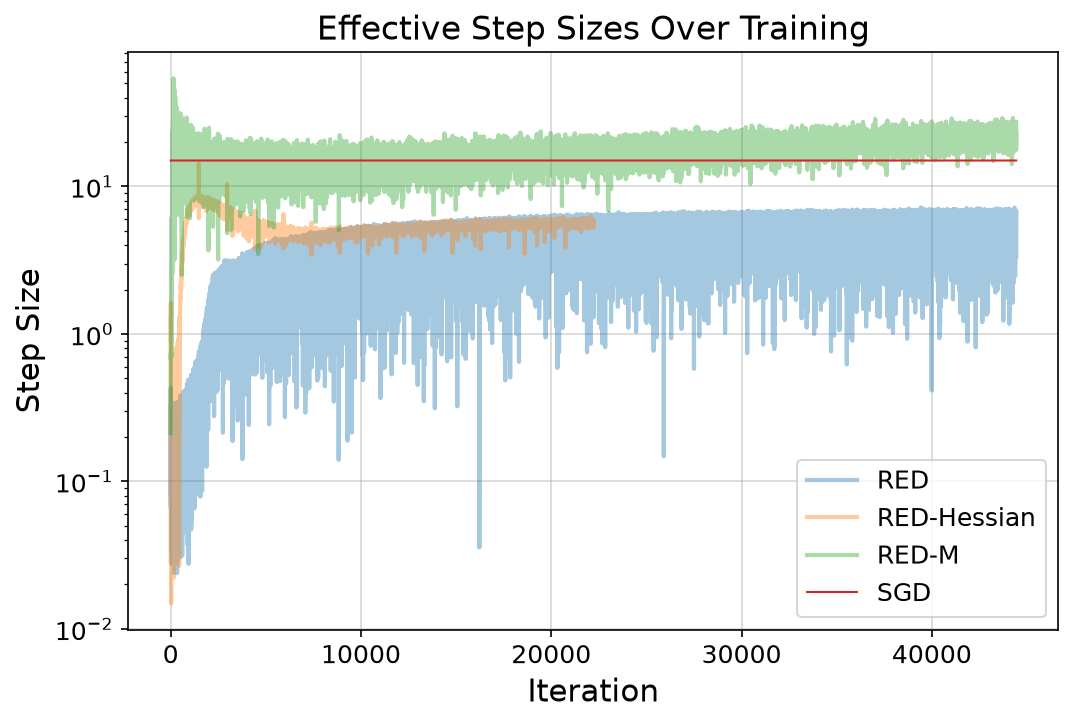

In [150]:
rk_red  = onp.array([t[2] for t in grad_history['red']])
rk_redh = onp.array([t[2] for t in grad_history['redhessian']])
rk_redm = onp.array([t[2] for t in grad_history['redm']])
print(rk_redm.shape)

plt.figure(figsize=(8,5))
plt.plot(rk_red, alpha=0.4, label=r'RED')
plt.plot(rk_redh, alpha=0.4, label=r'RED-Hessian')
plt.plot(rk_redm, alpha=0.4, label=r'RED-M')
plt.plot(grad_history['sgd'][:rk_redm.shape[0]], lw=1, label='SGD')
plt.yscale('log')
plt.title("Effective Step Sizes Over Training")
plt.xlabel('Iteration')
plt.ylabel('Step Size')
plt.legend()
plt.grid(alpha=0.5)
plt.savefig('step-sizes.png')
plt.show()

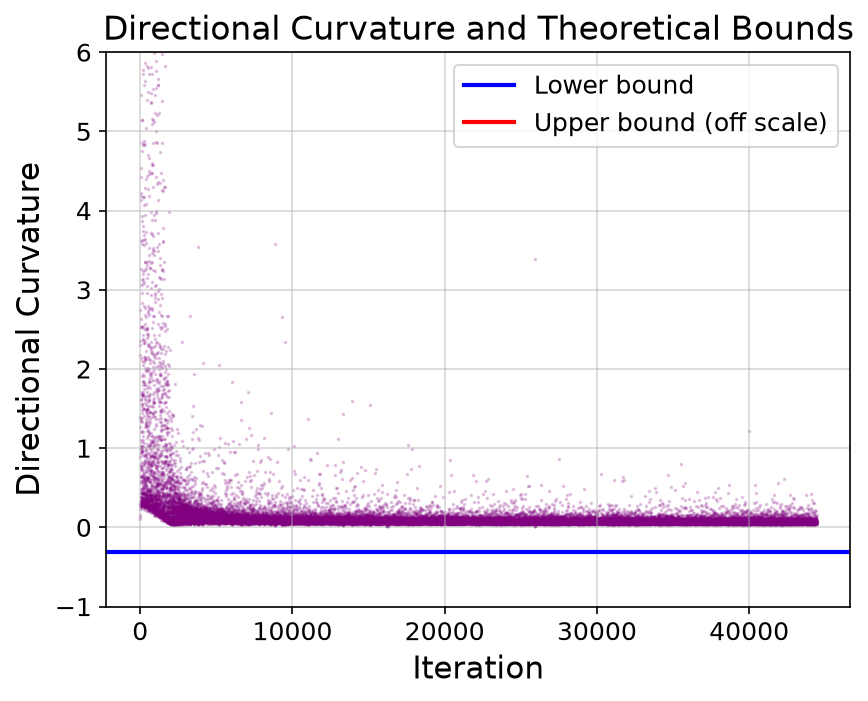

In [124]:
curve = onp.array([t[0] for t in grad_history['red']])
b_list = onp.array([t[1] for t in grad_history['red']])

C = 10
lower = -1/onp.sqrt(C)
upper = b_list**2 * (0.5 + 1 / (2*C)) + 1/onp.sqrt(C)

plt.scatter(range(len(curve)), curve, s=0.5, alpha=0.2, color='purple')
plt.axhline(lower, color='blue', label='Lower bound')
plt.axhline(upper[-1], color='red', label='Upper bound (off scale)')
plt.yscale('linear')
plt.ylim(-1, 6)
plt.xlabel('Iteration')
plt.ylabel('Directional Curvature')
plt.legend()
plt.title('Directional Curvature and Theoretical Bounds')
plt.savefig('curvature.png')
plt.grid(alpha=0.5)
plt.show()

In [17]:
batch = 8096

for optim2 in optimizers:
    N = networks[optim2][-1]
    loss_layer = Neur.Ilogit_and_KL(None)
    N_a = Neur.Network([N, loss_layer])

    total_loss = 0
    batches = 0

    for k in range(0, len(X_test), batch):
        X_cur = get_cbow(X_test[k:k+batch])
        Y_cur = get_one_hot(Y_test[k:k+batch])

        loss_layer.save_D = Y_cur.T
        loss = N_a.forward(X_cur.T)

        total_loss += loss
        batches += 1

    avg = total_loss / batches
    print(f"{optim2} Test Loss: {avg:.4f}")

redhessian Test Loss: 6.2996
sgd Test Loss: 6.3635
red Test Loss: 6.6558
adam Test Loss: 6.2761
adahessian Test Loss: 6.2963
redm Test Loss: 6.3196


1


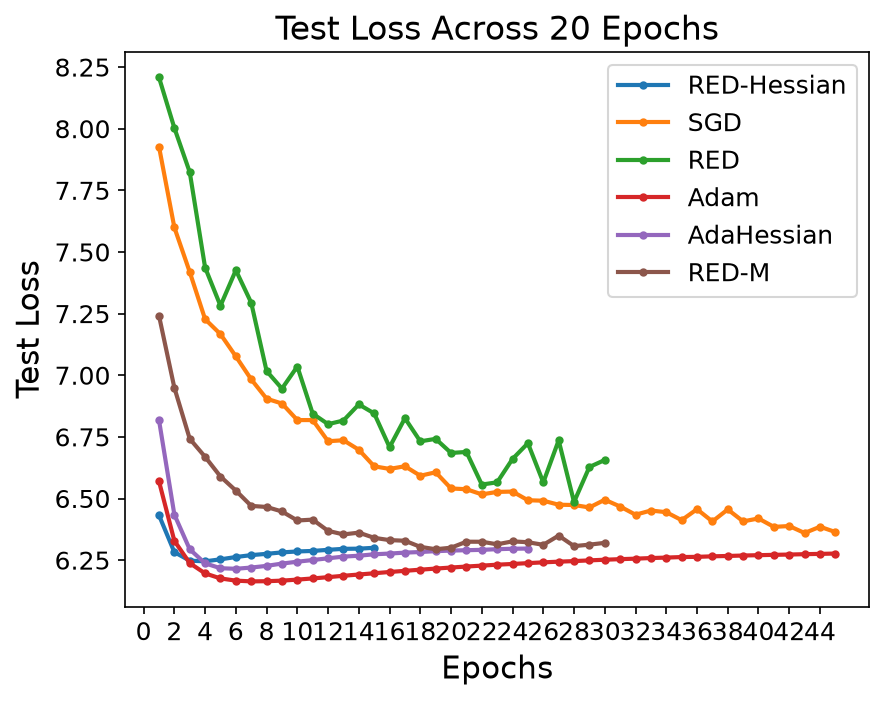

In [107]:
display = {"sgd": "SGD", "red": "RED", "redm": "RED-M", "adahessian": "AdaHessian", "adam": "Adam", "redhessian": "RED-Hessian"}
order = ['sgd', 'adam', 'adahessian', 'red', 'redm', 'redhessian']
def evaluate_and_plot_test_loss():
    test_losses = {optim: [] for optim in optimizers}
    batch_size = 4096
    print(1)
    for optim in order:
        for N in networks[optim]:
            loss_layer = Neur.Ilogit_and_KL(None)
            N_a = Neur.Network([N, loss_layer])
            total_loss = 0
            batches = 0
            for k in range(0, len(X_test), batch_size):
                X_cur = get_cbow(X_test[k : k + batch_size])
                Y_cur = get_one_hot(Y_test[k : k + batch_size])

                loss_layer.save_D = Y_cur.T
                loss = N_a.forward(X_cur.T)

                total_loss += loss
                batches += 1

            test_losses[optim].append(float(total_loss) / batches)

    for optim, losses in test_losses.items():
        plt.plot(range(1, epochs[optim]+1), losses, label=display[optim], marker="o", markersize=3)

    plt.xlabel("Epochs")
    plt.ylabel("Test Loss")
    plt.title("Test Loss Across 20 Epochs")
    plt.legend()
    plt.xticks(range(0, 46, 2))
    plt.show()
    return test_losses

test_losses = evaluate_and_plot_test_loss()

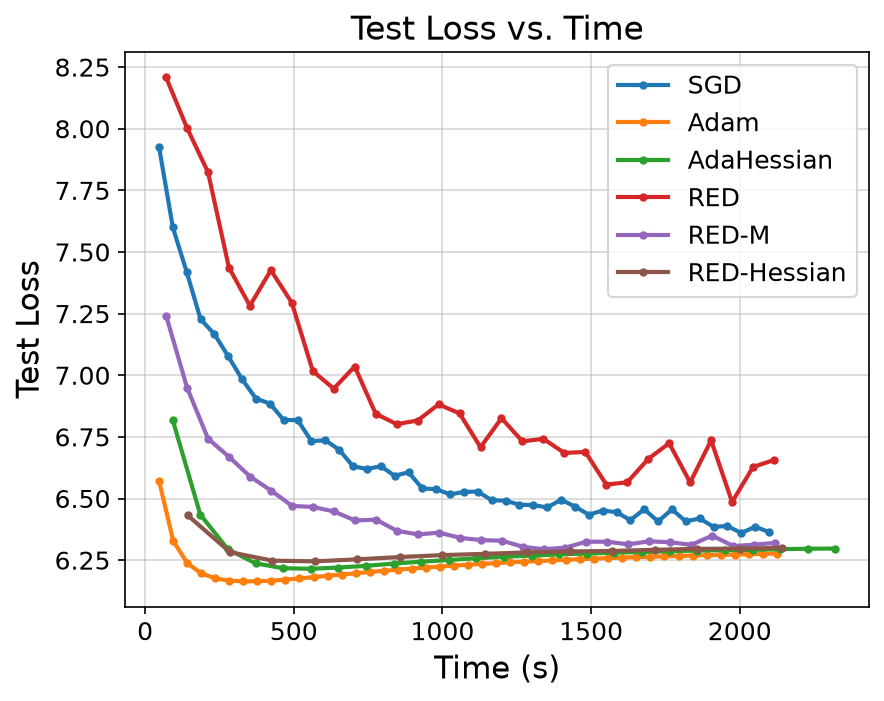

In [114]:
def test_vs_time():
    global test_losses
    plt.rcParams.update({'font.size': 14, 'axes.labelsize': 15, 'axes.titlesize': 16, 'legend.fontsize': 12, 'xtick.labelsize': 12, 'ytick.labelsize': 12, 'lines.linewidth': 2, 'figure.dpi': 150, 'savefig.bbox': 'tight'})
    for optim in order:
        losses = test_losses[optim]
        plt.plot(runtime[optim], losses, label=display[optim], marker="o", markersize=3)

    plt.xlabel("Time (s)")
    plt.ylabel("Test Loss")
    plt.title("Test Loss vs. Time")
    plt.grid(alpha=0.5)
    plt.legend()
    plt.savefig('test-vs-time.png')
    # return test_losses

test_vs_time()

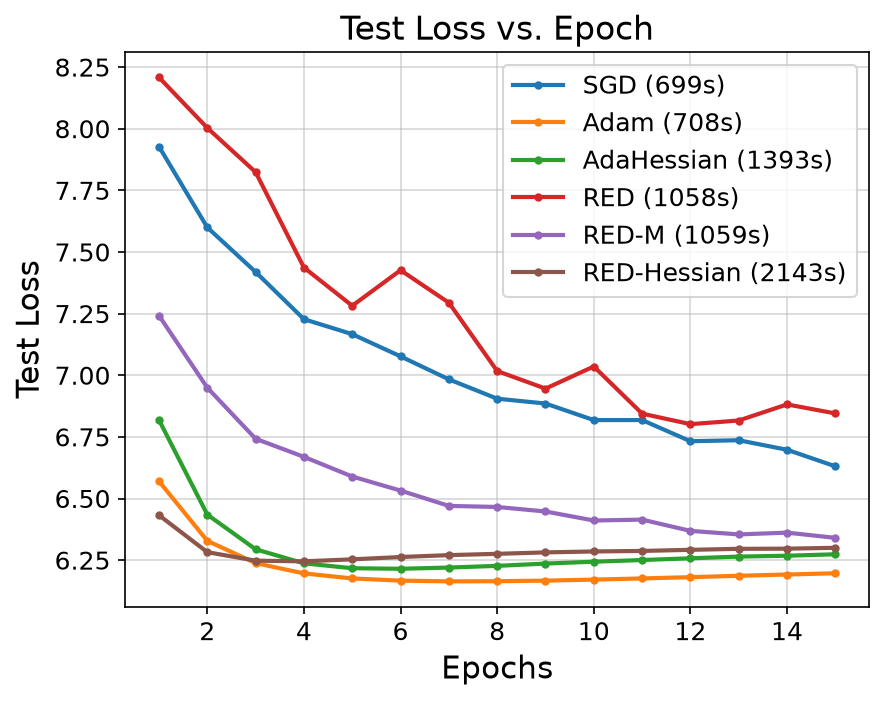

In [121]:
def test_vs_epoch():
    global test_losses
    for optim in order:
        losses = test_losses[optim]
        plt.plot(range(1,16), losses[:15], label=display[optim] + ' (' + str(round(runtime[optim][14])) + 's)', marker="o", markersize=3)

    plt.xlabel("Epochs")
    plt.ylabel("Test Loss")
    plt.title("Test Loss vs. Epoch")
    plt.grid(alpha=0.5)
    plt.legend()
    plt.savefig('test-vs-epoch.png')
    # return test_losses

test_vs_epoch()

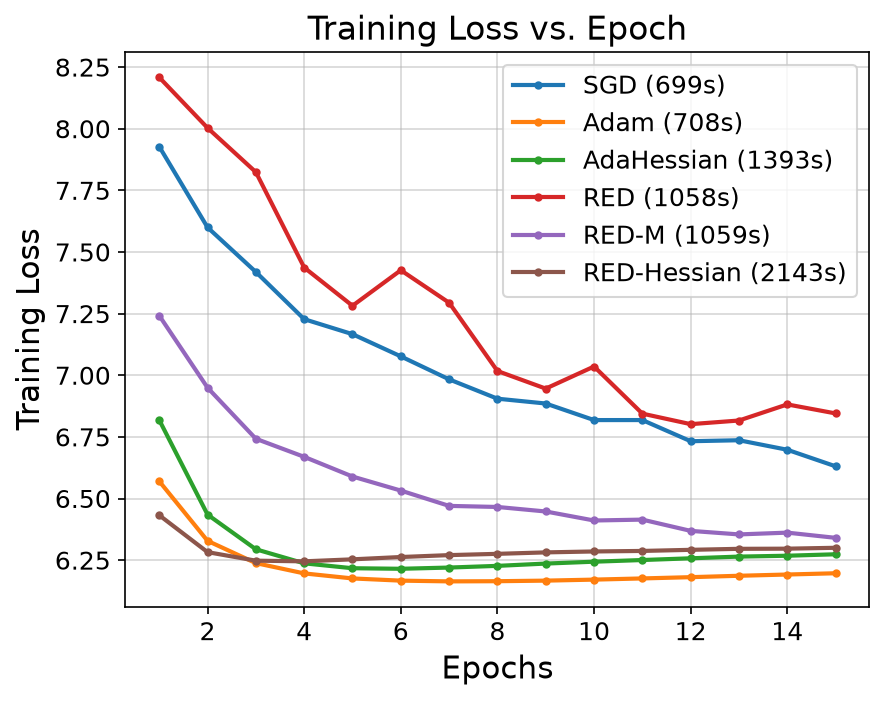

In [149]:
def train_vs_epoch():
    for optim in order:
        losses = test_losses[optim]
        plt.plot(range(1,16), losses[:15], label=display[optim] + ' (' + str(round(runtime[optim][14])) + 's)' , marker="o", markersize=3)

    plt.xlabel("Epochs")
    plt.ylabel("Training Loss")
    plt.title("Training Loss vs. Epoch")
    plt.grid(alpha=0.5)
    plt.legend()
    plt.savefig('train-vs-epoch.png')
    # return test_losses

train_vs_epoch()

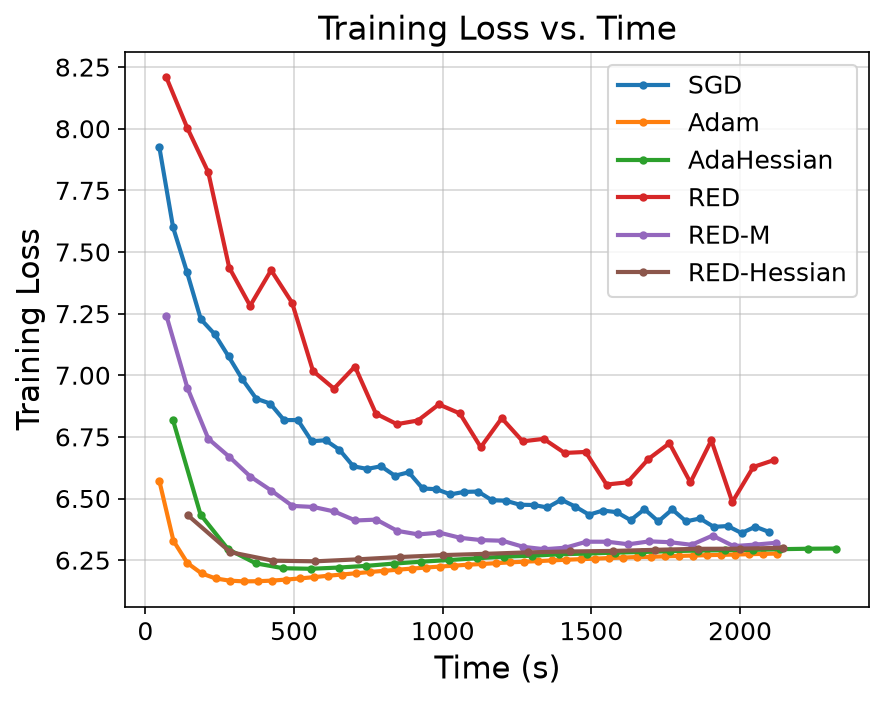

In [148]:
def train_vs_time():
    for optim in order:
        losses = test_losses[optim]
        plt.plot(runtime[optim], losses, label=display[optim], marker="o", markersize=3)

    plt.xlabel("Time (s)")
    plt.ylabel("Training Loss")
    plt.title("Training Loss vs. Time")
    plt.grid(alpha=0.5)
    plt.legend()
    plt.savefig('train-vs-time.png')
    # return test_losses

train_vs_time()

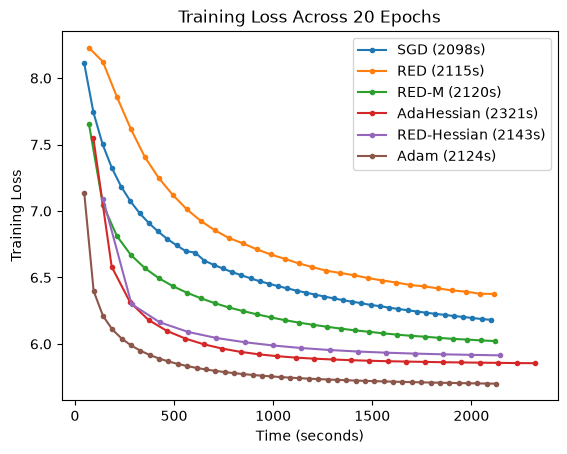

In [25]:
# train vs time

#plt.figure(figsize=(10,6))

plt.plot(runtime['sgd'], loss_history['sgd'], marker='o',markersize=3, label=f'SGD ({round(runtime['sgd'][-1])}s)')
plt.plot(runtime['red'], loss_history['red'], marker='o',markersize=3, label=f'RED ({round(runtime['red'][-1])}s)')
plt.plot(runtime['redm'], loss_history['redm'], marker='o',markersize=3, label=f'RED-M ({round(runtime['redm'][-1])}s)')
plt.plot(runtime['adahessian'], loss_history['adahessian'], marker='o', markersize=3, label=f'AdaHessian ({round(runtime['adahessian'][-1])}s)')
plt.plot(runtime['redhessian'], loss_history['redhessian'], marker='o', markersize=3, label=f'RED-Hessian ({round(runtime['redhessian'][-1])}s)')
plt.plot(runtime['adam'], loss_history['adam'], marker='o', markersize=3, label=f'Adam ({round(runtime['adam'][-1])}s)')

plt.xlabel('Time (seconds)')
plt.ylabel('Training Loss')
plt.title("Training Loss Across 20 Epochs")
#plt.xticks(np.arange(0, 21, 2).get())
plt.legend()
plt.show()

In [99]:
embed = networks['red'][-1].list_layers[0].A.T
norms = np.linalg.norm(embed, axis=1, keepdims=True)
norm_embed = embed / norms

def get_similar(word, top_k=5):
    if word not in dict:
        print(f"'{word}' not found.")
        return

    word_idx = dict[word]
    word_vec = norm_embed[word_idx]

    similar = norm_embed @ word_vec
    nearest = np.argsort(similar)[::-1]

    print(f"Words most similar to '{word}':")
    for i in range(1, top_k + 1):
        idx = int(nearest[i])
        score = similar[idx]
        print(f"  - {vocab[idx]}: {score:.4f}")

get_similar("king")
get_similar("apple")
get_similar("war")
get_similar("queen")
get_similar("battle")



Words most similar to 'king':
  - throne: 0.5929
  - kings: 0.5713
  - ruler: 0.5540
  - vi: 0.5433
  - northumbria: 0.5274
Words most similar to 'apple':
  - apples: 0.7573
  - iphone: 0.7390
  - ipad: 0.7255
  - ios: 0.6862
  - ipod: 0.6653
Words most similar to 'war':
  - occupation: 0.4767
  - wars: 0.4410
  - army: 0.4300
  - allies: 0.4289
  - soldiers: 0.4204
Words most similar to 'queen':
  - elizabeth: 0.6652
  - consort: 0.6351
  - princess: 0.6214
  - jubilee: 0.5948
  - monarch: 0.5755
Words most similar to 'battle':
  - battles: 0.7528
  - fought: 0.6417
  - armies: 0.6020
  - casualties: 0.5775
  - battlefield: 0.5500


In [15]:
def find_analogy(a, b, c, top_k=1):
    if any(w not in dict for w in [a, b, c]):
        print("One of the words is missing from the vocab.")
        return

    vec_a = norm_embed[dict[a]]
    vec_b = norm_embed[dict[b]]
    vec_c = norm_embed[dict[c]]

    target = vec_b - vec_a + vec_c
    target = target / np.linalg.norm(target)
    similar = norm_embed @ target
    nearest = np.argsort(similar)[::-1]

    print(f"'{a}' is to '{b}' as '{c}' is to:")

    count = 0
    for indx in nearest:
        idx = int(indx)
        word = vocab[idx]

        if word not in [a, b, c]:
            score = similar[idx]
            print(f"  {count + 1}. {word} ({score:.4f})")
            count += 1

        if count == top_k:
            break

find_analogy("man", "king", "woman", top_k=3) # queen
find_analogy("son", "father", "daughter", top_k=3) # mother
find_analogy("boy", "brother", "girl", top_k=3) # sister
find_analogy("paris", "france", "berlin", top_k=3) # germany
find_analogy("france", "paris", "japan", top_k=3) # tokyo
find_analogy("bright", "dark", "white", top_k=3) # black
find_analogy("small", "smaller", "big", top_k=3) # bigger
find_analogy("writing", "wrote", "making", top_k=3) # made
find_analogy("america", "american", "canada", top_k=3) # canadian


'man' is to 'king' as 'woman' is to:
  1. queen (0.5774)
  2. throne (0.5404)
  3. consort (0.5277)
'son' is to 'father' as 'daughter' is to:
  1. grandmother (0.7986)
  2. mother (0.7909)
  3. parents (0.7187)
'boy' is to 'brother' as 'girl' is to:
  1. sister (0.7448)
  2. younger (0.6668)
  3. daughter (0.6240)
'paris' is to 'france' as 'berlin' is to:
  1. brandenburg (0.5724)
  2. germanys (0.5477)
  3. nazi (0.4802)
'france' is to 'paris' as 'japan' is to:
  1. tokyo (0.4934)
  2. osaka (0.4652)
  3. kobe (0.4420)
'bright' is to 'dark' as 'white' is to:
  1. black (0.6256)
  2. whites (0.4961)
  3. stripes (0.4439)
'small' is to 'smaller' as 'big' is to:
  1. bigger (0.6124)
  2. bang (0.4905)
  3. biggest (0.4214)
'writing' is to 'wrote' as 'making' is to:
  1. made (0.5397)
  2. make (0.4749)
  3. makers (0.3865)
'america' is to 'american' as 'canada' is to:
  1. canadian (0.6558)
  2. ontario (0.4230)
  3. manitoba (0.3937)


In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

def cosine_heatmap(words, embed, title):
    embed = embed.get()
    idx = [dict[w] for w in words]
    
    cur_embed = embed[idx]
    norms = onp.linalg.norm(cur_embed, axis=1, keepdims=True)
    norm_embed = cur_embed / norms
    sim = norm_embed @ norm_embed.T
    mask = onp.eye(len(words), dtype=bool)

    plt.figure(figsize=(len(words) + 2, len(words) + 2))
    sns.heatmap(sim, xticklabels=words, yticklabels=words, cmap="coolwarm", vmin=-0.5, vmax=1, square=True, mask=mask)
    
    plt.title(title)
    plt.savefig("heatmap.png")
    plt.show()
    return sim

words = ["father", "mother", "son", "daughter", "war", "army", "battle", "apple"]
embed = networks['redhessian'][1].list_layers[0].A.T
cosine_heatmap(words, embed, title="RED-Hessian embeddings")

KeyError: 'redhessian'

In [139]:
def run_simlex_benchmark(filepath, norm_embed):
    simlex, model = [], []

    with open(filepath, 'r') as f:
        next(f)
        for line in f:
            parts = line.strip().lower().split('\t')

            if len(parts) >= 4 and parts[0] in vocab_st and parts[1] in vocab_st:
                simlex.append(float(parts[3]))
                cos_sim = onp.dot(norm_embed[dict[parts[0]]], norm_embed[dict[parts[1]]])
                model.append(cos_sim)

    # spearman rank correlation
    n = len(simlex)
    d_sq = (onp.argsort(onp.argsort(simlex)) - onp.argsort(onp.argsort(model))) ** 2
    res = 1 - (6 * np.sum(d_sq)) / (n * (n ** 2 - 1))
    print("Simlex999 benchmark:")
    print(f"Data size: {n}")
    print(f"Spearman's Rho: {res:.4f}\n")

def run_wordsim_benchmark(filepath, norm_embed):
    wordsim, model = [], []

    with open(filepath, 'r') as f:
        next(f)
        for line in f:
            parts = line.strip().lower().split(',')

            if len(parts) >= 3 and parts[0] in vocab_st and parts[1] in vocab_st:
                wordsim.append(float(parts[2]))
                cos_sim = onp.dot(norm_embed[dict[parts[0]]], norm_embed[dict[parts[1]]])
                model.append(cos_sim)

    # spearman rank correlation
    n = len(wordsim)
    d_sq = (onp.argsort(onp.argsort(wordsim)) - onp.argsort(onp.argsort(model))) ** 2
    res = 1 - (6 * np.sum(d_sq)) / (n * (n ** 2 - 1))

    print("WordSim353 benchmark:")
    print(f"Data size: {n}")
    print(f"Spearman's Rho: {res:.4f}\n")

tests = []
valid = 0

def google_setup(path):
    global tests, valid, ga, gb, gc, gans
    with open(path, 'r') as f:
        for line in f:
            line = line.strip().lower()
            words = line.split()
            if len(words) == 4 and all(w in vocab_st for w in words):
                tests.append(tuple(dict[w] for w in words))
                valid += 1

        tests = onp.array(tests)
        ga, gb, gc, gans = tests[:, 0], tests[:, 1], tests[:, 2], tests[:, 3]
        

def run_google_benchmark(norm_embed, k=5):
    targets = norm_embed[gb] - norm_embed[ga] + norm_embed[gc]
    targets /= onp.linalg.norm(targets, axis=1, keepdims=True)
    similars = targets @ norm_embed.T
    use = onp.arange(valid)
    similars[use, ga] = similars[use, gb] = similars[use, gc] = -100
    preds = onp.argsort(similars, axis=1)[:, -k:]
    acck = (preds == gans[:, None]).any(axis=1).mean() * 100

    return acck

"""
google_setup("questions-words.txt")
for optim3 in optimizers:
    best = int(onp.argmin(test_losses[optim3]))
    print(best)
    embed2 = networks[optim3][best].list_layers[0].A.T.get()
    # embed2 = networks[optim3][4].list_layers[0].A.T.get()
    norms2 = onp.linalg.norm(embed2, axis=1, keepdims=True)
    norm_embed2 = embed2 / norms2
    print(f"===== {optim3} =====")
    run_simlex_benchmark("SimLex-999.txt", norm_embed2)
    run_wordsim_benchmark("wordsim353crowd.csv", norm_embed2)
    print("Google benchmark:")
    print(f"Top-1 Accuracy: ({run_google_benchmark(norm_embed2, k=1):.2f}%)")
    print(f"Top-3 Accuracy: ({run_google_benchmark(norm_embed2, k=3):.2f}%)")
    print(f"Top-5 Accuracy: ({run_google_benchmark(norm_embed2, k=5):.2f}%)\n")

"""
google_setup("questions-words.txt")
google1 = {optim: [] for optim in optimizers}
for optim3 in optimizers:
    for e in range(epochs[optim3]):
        embed2 = networks[optim3][e].list_layers[0].A.T.get()
        norms2 = onp.linalg.norm(embed2, axis=1, keepdims=True)
        norm_embed2 = embed2 / norms2
        acc = run_google_benchmark(norm_embed2, k=1)
        google1[optim3].append(acc)
        print(f"{optim3} epoch {e}: {acc}")

redhessian epoch 0: 50.837438423645324
redhessian epoch 1: 52.20267417311752
redhessian epoch 2: 47.06544686840253
redhessian epoch 3: 40.83040112596763
redhessian epoch 4: 35.05981703026038
redhessian epoch 5: 29.697396199859256
redhessian epoch 6: 27.037297677691768
redhessian epoch 7: 25.362420830401128
redhessian epoch 8: 25.601688951442647
redhessian epoch 9: 24.771287825475017
redhessian epoch 10: 24.54609429978888
redhessian epoch 11: 24.883884588318086
redhessian epoch 12: 24.813511611541166
redhessian epoch 13: 24.517945109078116
redhessian epoch 14: 23.940886699507388
sgd epoch 0: 9.092188599577762
sgd epoch 1: 17.832512315270936
sgd epoch 2: 25.052779732582685
sgd epoch 3: 30.893736805066858
sgd epoch 4: 35.48205489092189
sgd epoch 5: 39.47923997185081
sgd epoch 6: 41.970443349753694
sgd epoch 7: 43.81421534130894
sgd epoch 8: 45.27797325826882
sgd epoch 9: 46.89655172413793
sgd epoch 10: 47.881773399014776
sgd epoch 11: 48.89514426460239
sgd epoch 12: 49.89444053483462
sgd 

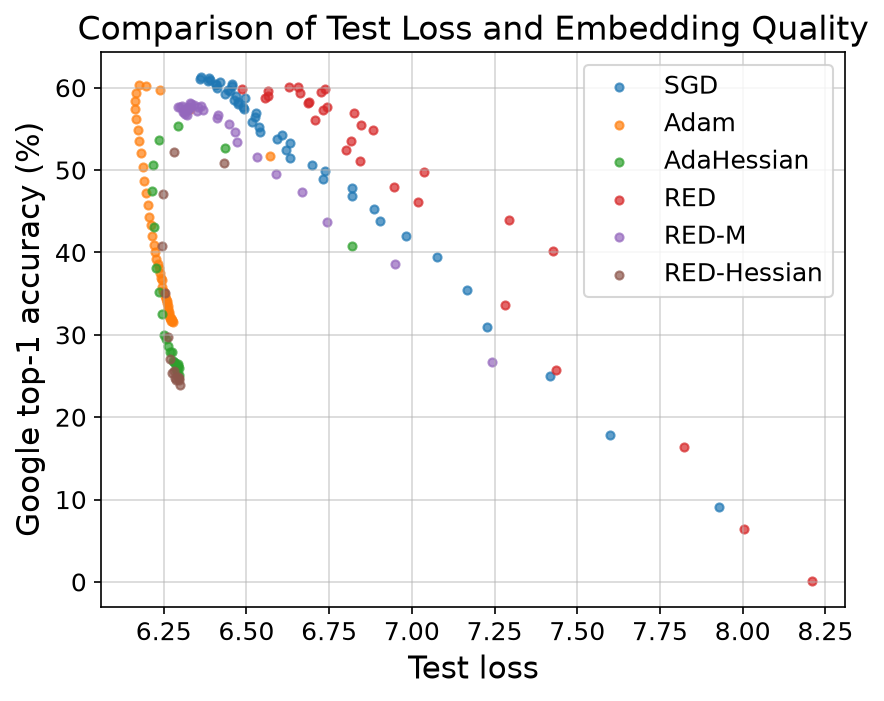

In [146]:
for optim in order:
    plt.scatter(test_losses[optim], google1[optim], label=display[optim], s=15, alpha=0.7)

plt.xlabel('Test loss')
plt.ylabel('Google top-1 accuracy (%)')
plt.title('Comparison of Test Loss and Embedding Quality')
plt.grid(alpha=0.5)
plt.legend()
plt.savefig('loss_vs_quality.png')
plt.show()

In [15]:
np.savez("embeds7.npz", **{o: networks[o][-1].list_layers[0].A.T.get() for o in optimizers})
for o in optimizers:
    print(o)
print(1)

adam
redhessian
redm
red
adahessian
sgd
1


In [33]:
d = onp.load("embeds.npz")
print(d.files)
print(d['adahessian'].shape)

['adam', 'redhessian', 'redm', 'red', 'adahessian', 'sgd']
(10000, 300)


In [16]:
## Backup arrays & testing with backups

import json
import pickle

# backup
with open("vocab_7.json", "w") as f:
    json.dump({'vocab': vocab, 'dict': dict}, f)

with open("plot_data_7.pkl", "wb") as f:
    pickle.dump({
        'loss_history': loss_history,
        'grad_history': grad_history,
        'loss_history_2': test_losses,
        'runtime': runtime
    }, f)

all_embed = {}
for optim4 in optimizers:
    embed3 = networks[optim4][-1].list_layers[0].A.T
    norms3 = np.linalg.norm(embed3, axis=1, keepdims=True)
    all_embed[optim4] = embed3 / norms3

np.savez("all_word_vectors_7.npz", **all_embed)

